# **Exploratory Data Analysis (EDA) - Customer Behavior Analysis**

**Goal:** This report performs exploratory data analysis (EDA) on the customer dataset to identify patterns, understand demographic characteristics, and find early insights into shopping behavior. The analysis covers three main objectives:
1.  **Descriptive statistics:** Understand the statistical summary of the data.
2.  **Visual analysis:** Answer key questions through data visualization.
3.  **Initial findings and hypotheses:** Formulate insights and hypotheses from the analysis.

> **Data:** run `data_cleaning.ipynb` in `module-03-data-cleaning/` first; it writes `data/processed/mall_customers_clean.csv` (a generated copy is already included in the repository).

### **1. Import Libraries**
Import all Python libraries needed for the analysis: pandas for data manipulation, and matplotlib and seaborn for data visualization.

In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

### **2. Load Dataset**
Load the cleaned dataset from the previous assignment into a pandas DataFrame, then show the first five rows to confirm it loaded correctly.

In [2]:
df = pd.read_csv(Path('../data/processed/mall_customers_clean.csv'))
df.head()

,customer_id,gender,age,annual_income_k_usd,spending_score
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


## **Objective 1: Descriptive Statistics**
In this section we look at the statistical summary of the data to get a basic understanding of the distribution and central tendency of each variable.

#### **1.1 Numerical Data Analysis**
Show descriptive statistics (mean, standard deviation, minimum, maximum, and quartiles) for all numerical columns.

In [3]:
print("\n--- Descriptive Statistics for Numerical Data ---")
print(df[['age', 'annual_income_k_usd', 'spending_score']].describe().T)


--- Descriptive Statistics for Numerical Data ---
                     count   mean        std   min    25%   50%   75%    max
age                  200.0  38.85  13.969007  18.0  28.75  36.0  49.0   70.0
annual_income_k_usd  200.0  60.51  26.122824  15.0  41.50  61.5  78.0  132.0
spending_score       200.0  50.20  25.823522   1.0  34.75  50.0  73.0   99.0


From the descriptive statistics of the numerical data we get some first insights into customer characteristics:

* **`age`**:
    * The mean customer age is about **38.85 years**, with a wide range from **18 to 70 years**.
    * Half of the customers are younger than **36 years** (median / 50%), which indicates a fairly mature customer population that also includes young adults.

* **`annual_income_k_usd`**:
    * The mean annual income is **$60,510 USD**.
    * Income varies widely, from **$15,000 USD** to **$132,000 USD**. The high standard deviation (about 26.12) also confirms a wide income gap among customers.

* **`spending_score`**:
    * The spending score (scale 1-100) has a nearly equal mean and median, **50.2** and **50.0**, indicating a fairly symmetric distribution centered in the middle.
    * The score range of **1 to 99** shows the dataset covers every kind of shopping behavior, from very frugal to very free-spending.

#### **1.2 Categorical Data Analysis**
Count the frequency of each category in the 'gender' column to understand the demographic composition of the customers.

In [4]:
print("\n--- Descriptive Statistics for Categorical Data (Gender) ---")
print(df['gender'].value_counts())


--- Descriptive Statistics for Categorical Data (Gender) ---
gender
Female    112
Male       88
Name: count, dtype: int64


The categorical analysis gives a picture of the demographic composition of the customers:

* **`gender`**:
    * The dataset consists of **112 female customers** and **88 male customers**.
    * There are more female than male customers, a fact to keep in mind for further analysis because shopping preferences or behavior may differ between genders.

## **Objective 2: Visual Analysis**
In this section we create visualizations to answer several key questions about the customer data.

### **Question 1: How is customer age distributed? Does a particular age group stand out?**
To answer this we use a histogram to see how many customers fall in each age range.

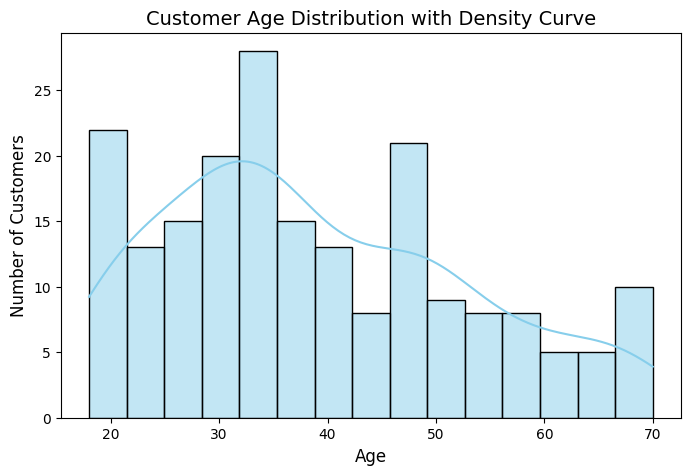

In [5]:
plt.figure(figsize=(8, 5))
sns.histplot(df["age"], bins=15, kde=True, color="skyblue", edgecolor="black")

plt.title("Customer Age Distribution with Density Curve", fontsize=14)
plt.xlabel("Age", fontsize=12)
plt.ylabel("Number of Customers", fontsize=12)
plt.show()

**Answer and interpretation:**

Yes, a particular age group stands out. From the histogram above we can conclude:
-   **Dominant age group:** The distribution peaks between 20 and 40 years, with the largest concentration around 30-35. Most customers are therefore young to early-middle-aged adults.
-   **Drop in customers:** After age 40 the number of customers falls significantly, and it is smallest in the 60+ group.
-   **Density curve (KDE):** The density curve reinforces the histogram, showing a clear peak in the younger group and a tail that extends toward older ages.

### **Question 2: How does the average spending score compare between male and female customers?**
We compute the average spending score for each gender and visualize it with a bar chart for a clear comparison.

In [6]:
# average spending score per gender
avg_spending = df.groupby("gender")["spending_score"].mean().reset_index()
print(avg_spending)

   gender  spending_score
0  Female       51.526786
1    Male       48.511364


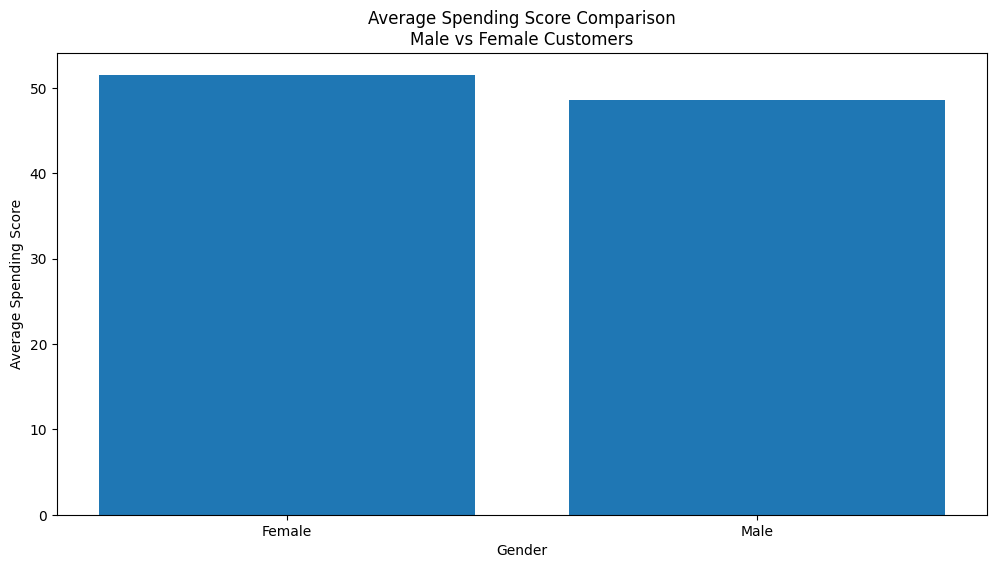

In [7]:
plt.figure(figsize=(12, 6))
plt.bar(avg_spending["gender"], avg_spending["spending_score"])
plt.title("Average Spending Score Comparison\nMale vs Female Customers")
plt.xlabel("Gender")
plt.ylabel("Average Spending Score")
plt.show()

**Answer and interpretation:**

Based on the calculation and the bar chart:
-   The average spending score of **female (51.53)** customers is slightly higher than that of **male (48.51)** customers.
-   Although there is a difference, the gap is not large. On average, there is no very significant difference in shopping behavior between the two genders in this dataset, although female customers tend to have a slightly higher spending score.

### **Question 3: Is annual income related to spending score? Do high-income customers tend to have high spending scores?**
A scatter plot is the most effective tool for exploring the relationship between two numerical variables such as income and spending score.

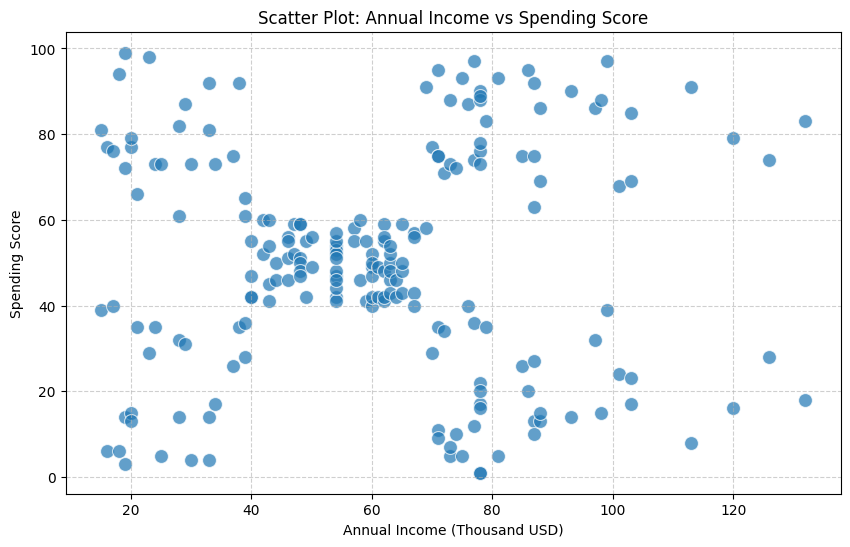

In [8]:
plt.figure(figsize=(10, 6))
sns.scatterplot(x='annual_income_k_usd', y='spending_score', data=df, s=100, alpha=0.7)
plt.title('Scatter Plot: Annual Income vs Spending Score')
plt.xlabel('Annual Income (Thousand USD)')
plt.ylabel('Spending Score')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

**Answer and interpretation:**

The scatter plot shows **no simple linear relationship** between annual income and spending score. High-income customers do not automatically have a high spending score.

Instead, we can identify several clear **clusters or customer segments**:
1.  **Low income, high score:** Free spenders despite a lower income (top left).
2.  **Low income, low score:** Frugal customers with a low income (bottom left).
3.  **Mid income, mid score:** A large group in the middle with moderate shopping behavior.
4.  **High income, high score:** The "ideal" customers who earn a lot and like to shop (top right).
5.  **High income, low score:** High-income customers who are very frugal (bottom right).

This shows that the relationship between income and spending is more complex and better analyzed with segmentation than with a simple correlation.

## **Objective 3: Initial Findings (Insights) and Hypotheses**
Based on the overall statistical and visual analysis, here are the key findings and hypotheses that can be formulated for further analysis.

### **Initial Findings (Insights)**
1.  **The core customer base is young adults:** Most customers (the highest concentration) are aged 20-40. This is the most important demographic segment for the business.
2.  **Gender is not a main driver of shopping behavior:** Although the average spending score of women is slightly higher, the difference is very small. A marketing strategy focused on gender alone is therefore likely to be ineffective.
3.  **Customer segmentation matters more than correlation:** The strongest insight from this EDA is the five distinct customer segments based on the combination of income and spending score. Shopping behavior cannot be predicted from income alone.

### **Hypotheses**
1.  **Hypothesis 1:** A marketing strategy personalized by customer segment (e.g., targeting luxury-goods promotions to the 'High Income, High Score' cluster and discounts to the 'Low Income, High Score' cluster) will achieve a much higher conversion rate than a mass marketing campaign.
2.  **Hypothesis 2:** The 'High Income, Low Score' customer group most likely prioritizes saving or investing. They could be a target for financial products or high-quality, long-lasting goods rather than consumer goods.